# Profiled training step, as a graph

The capture below runs one training step (forward, next-token loss, backward, and AdamW update) under `torch.profiler` on a Modal T4 and returns
`serialize(prof)`: one plain dictionary per event of `prof.events()`, in that order. Nothing
live comes back, so everything below is ordinary Python.

A row's identity is `index`, its position in `prof.events()`. Two kinds of edge join the rows:

- `parent` / `children` — synchronous CPU nesting, taken from `cpu_parent`.
- `launcher` / `gpu_activities` — the asynchronous launch edge, taken from the CUPTI
  correlation id. A GPU activity is a row of its own, with its own start, end and stream.
Five complete training steps warm up the model and optimizer before capture.
Phase scopes (`train::forward`, `train::loss`, `train::backward`,
`train::optimizer_step`, and `train::zero_grad`) are retained in branch provenance.
The FQN hooks cover forward calls only: loss, backward, and optimizer kernels
without a module scope remain in the unattributed group and are included in the
partition and timeline. Backward module attribution is not inferred from CPU ancestry.


## Module attribution helpers

Record module FQNs around forward calls, assign each kernel to its innermost scope,
and partition those branches into module groups.


In [1]:
from contextlib import contextmanager
from threading import local

MODULE_SCOPE = "module_fqn::"


@contextmanager
def module_scopes(model, root: str = "model"):
    """Record FQNs around eager module calls; remove all hooks on exit.

    Shared modules use the alias below the active caller when possible, otherwise
    the first named_modules path. Two aliases under the same caller are ambiguous
    to hooks and use the first path. Direct .forward() calls bypass module hooks.
    """
    from torch.profiler import record_function

    aliases = {}
    for name, module in model.named_modules(remove_duplicate=False):
        aliases.setdefault(module, []).append(f"{root}.{name}" if name else root)
    state = local()
    handles = []

    def enter(module, args):
        if not hasattr(state, "stack"):
            state.stack = []
        paths = aliases[module]
        caller = state.stack[-1][1] if state.stack else None
        candidates = [p for p in paths if caller and p.startswith(caller + ".")]
        fqn = (candidates or paths)[0]
        scope = record_function(MODULE_SCOPE + fqn)
        scope.__enter__()
        state.stack.append((module, fqn, scope))

    def leave(module, args, output):
        stack = getattr(state, "stack", [])
        if stack and stack[-1][0] is module:
            stack.pop()[2].__exit__(None, None, None)

    try:
        for module in aliases:
            handles.append(module.register_forward_pre_hook(enter, prepend=True))
            handles.append(module.register_forward_hook(leave, always_call=True))
        yield
    finally:
        for handle in handles:
            handle.remove()


In [2]:
def module_branches(
    rows: list[dict], *, kernels_only: bool = True,
) -> tuple[list[dict], list[dict]]:
    """Return (attributed, unattributed), retaining one full branch per device event.

    Branch indices run from GPU event to CPU root. Uncorrelated events and work
    outside instrumented modules have module_fqn and module_path set to None;
    their event identity, ancestry and timing are retained in unattributed.
    """
    by_index = {r["index"]: r for r in rows}
    if len(by_index) != len(rows):
        raise ValueError("Event indices must be unique")
    attributed, unattributed = [], []
    for row in rows:
        if row["device_type"] == "DeviceType.CPU":
            continue
        if kernels_only and row["activity_type"] != "kernel":
            continue
        branch, modules, seen = [row["index"]], [], {row["index"]}
        index = row["launcher"]
        while index is not None:
            if index in seen:
                raise ValueError(f"Cycle on branch for event {row['index']}")
            seen.add(index)
            node = by_index[index]
            branch.append(index)
            if node["name"].startswith(MODULE_SCOPE):
                modules.append(node["name"].removeprefix(MODULE_SCOPE))
            index = node["parent"]
        destination = attributed if modules else unattributed
        destination.append({
            "index": row["index"],
            "module_fqn": modules[0] if modules else None,
            "module_path": list(reversed(modules)) if modules else None,
            "branch": branch,
            "kernel": row["name"],
            "duration_us": row["duration_us"],
            "start_us": row["start_us"],
            "end_us": row["end_us"],
        })
    return attributed, unattributed


In [3]:
def aggregate_modules(branches: list[dict], *, depth: int | None = None) -> list[dict]:
    """Partition exclusive assignments by FQN, optionally truncated to dot depth.

    Root 'model' has depth 1. Duration is summed GPU execution time, not wall
    time: concurrent kernels can overlap. Each invocation keeps its event index.
    If unattributed branches are included, they form a separate None group.
    At every depth, event_indices are pairwise disjoint and their union is exactly
    the input event indices. Parent rows contain only their own assigned kernels,
    not kernels assigned to separately listed descendants. Duplicate input event
    indices are rejected, including duplicates with different module owners.
    Each group's branches retain the individual kernel events and provenance.
    start_us/end_us bound those kernels tightly; span_us includes intervening
    gaps. Group intervals can overlap even though kernel membership is disjoint.
    """
    if depth is not None and (not isinstance(depth, int) or depth < 1):
        raise ValueError("depth must be a positive integer or None")
    groups, seen = {}, set()
    for branch in branches:
        index = branch["index"]
        if index in seen:
            raise ValueError(f"Duplicate device event {index}")
        seen.add(index)
        fqn = branch["module_fqn"]
        if depth is not None and fqn is not None:
            fqn = ".".join(fqn.split(".")[:depth])
        group = groups.setdefault(fqn, {
            "module_fqn": fqn, "launches": 0, "gpu_time_us": 0.0,
            "event_indices": [], "branches": [],
            "start_us": branch["start_us"], "end_us": branch["end_us"],
        })
        group["launches"] += 1
        group["gpu_time_us"] += branch["duration_us"]
        group["event_indices"].append(index)
        group["branches"].append(branch)
        group["start_us"] = min(group["start_us"], branch["start_us"])
        group["end_us"] = max(group["end_us"], branch["end_us"])
    for group in groups.values():
        group["span_us"] = group["end_us"] - group["start_us"]
    return sorted(groups.values(), key=lambda g: (-g["gpu_time_us"], g["module_fqn"] or ""))


In [4]:
import torch
from torch import nn
from models.transformer import ModelParameters, build

# All models accept the same integer tensor [batch, sequence] and return
# logits [batch, sequence, vocabulary]. Construct on CPU for transport to Modal.
model_parameters = ModelParameters(
    vocab_size=1000, sequence_length=64, num_layers=5,
    d_model=64, d_ff=64, num_heads=2, rope_theta=10000,
    device="cpu", dtype="torch.float32",
)


class BuiltinLM(nn.Module):
    def __init__(self, params):
        super().__init__()
        self.embedding = nn.Embedding(params.vocab_size, params.d_model)
        self.encoder = nn.TransformerEncoder(
            nn.TransformerEncoderLayer(
                d_model=params.d_model, nhead=params.num_heads,
                dim_feedforward=params.d_ff, batch_first=True,
            ), num_layers=params.num_layers,
        )
        self.norm = nn.LayerNorm(params.d_model)
        self.linear = nn.Linear(params.d_model, params.vocab_size)

    def forward(self, tokens):
        x = self.embedding(tokens)
        mask = torch.ones(tokens.shape[1], tokens.shape[1],
                          device=tokens.device, dtype=torch.bool).triu(1)
        return self.linear(self.norm(self.encoder(x, mask=mask)))


class SimpleMLP(nn.Module):
    """Token-wise MLP baseline with the same input/output contract."""
    def __init__(self, params):
        super().__init__()
        self.embedding = nn.Embedding(params.vocab_size, params.d_model)
        self.mlp = nn.Sequential(
            nn.Linear(params.d_model, params.d_ff), nn.ReLU(),
            nn.Linear(params.d_ff, params.d_model), nn.ReLU(),
        )
        self.linear = nn.Linear(params.d_model, params.vocab_size)

    def forward(self, tokens):
        return self.linear(self.mlp(self.embedding(tokens)))


def make_model(kind):
    torch.manual_seed(0)
    factories = {"builtin": BuiltinLM, "mlp": SimpleMLP, "ours": build}
    return factories[kind](model_parameters)


# Change only this selection to profile another architecture.
model_kind = "ours"  # "builtin", "mlp", or "ours"
model = make_model(model_kind)
tokens = torch.randint(
    0, model_parameters.vocab_size, (8, model_parameters.sequence_length),
    generator=torch.Generator().manual_seed(0),
)


In [5]:
from profile_events import app, image, serialize


@app.function(image=image, gpu="T4", timeout=300)
def capture(model, tokens) -> list[dict]:
    import torch
    from torch import nn
    from torch.profiler import ProfilerActivity, profile, record_function

    torch.manual_seed(0)
    model = model.to("cuda")
    tokens = tokens.to("cuda")
    model.train()
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
    # Next-token prediction: each position predicts the following input token.
    targets = tokens[:, 1:].reshape(-1)

    def train_step():
        with record_function("train::zero_grad"):
            optimizer.zero_grad(set_to_none=True)
        with record_function("train::forward"):
            logits = model(tokens)
        with record_function("train::loss"):
            loss = nn.functional.cross_entropy(
                logits[:, :-1, :].reshape(-1, logits.shape[-1]), targets
            )
        with record_function("train::backward"):
            loss.backward()
        with record_function("train::optimizer_step"):
            optimizer.step()

    # Warm up backward kernels and initialize AdamW state before profiling.
    for _ in range(5):
        train_step()
    torch.cuda.synchronize()

    with module_scopes(model), profile(
        activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA],
        record_shapes=True,
        with_stack=True,
        with_flops=True,
        profile_memory=True,
        
    ) as prof:
        for _ in range(1):
            train_step()
        torch.cuda.synchronize()
    return serialize(prof)


In [6]:
# The selected CPU model and the shared input tensor are passed explicitly.
with app.run():
    rows = capture.remote(model, tokens)

print(f"{model_kind}: {len(rows)} events, "
      f"{sum(r['device_type'] != 'DeviceType.CPU' for r in rows)} GPU activities")


ours: 14318 events, 879 GPU activities


## The rows as a table

The edge columns are lists of `index`, so any walk over the graph is a join back onto this
frame.

/var/folders/_9/c3pgt8bn23n2jqgj_1cfghrm0000gn/T/ipykernel_59361/2340455528.py:36: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


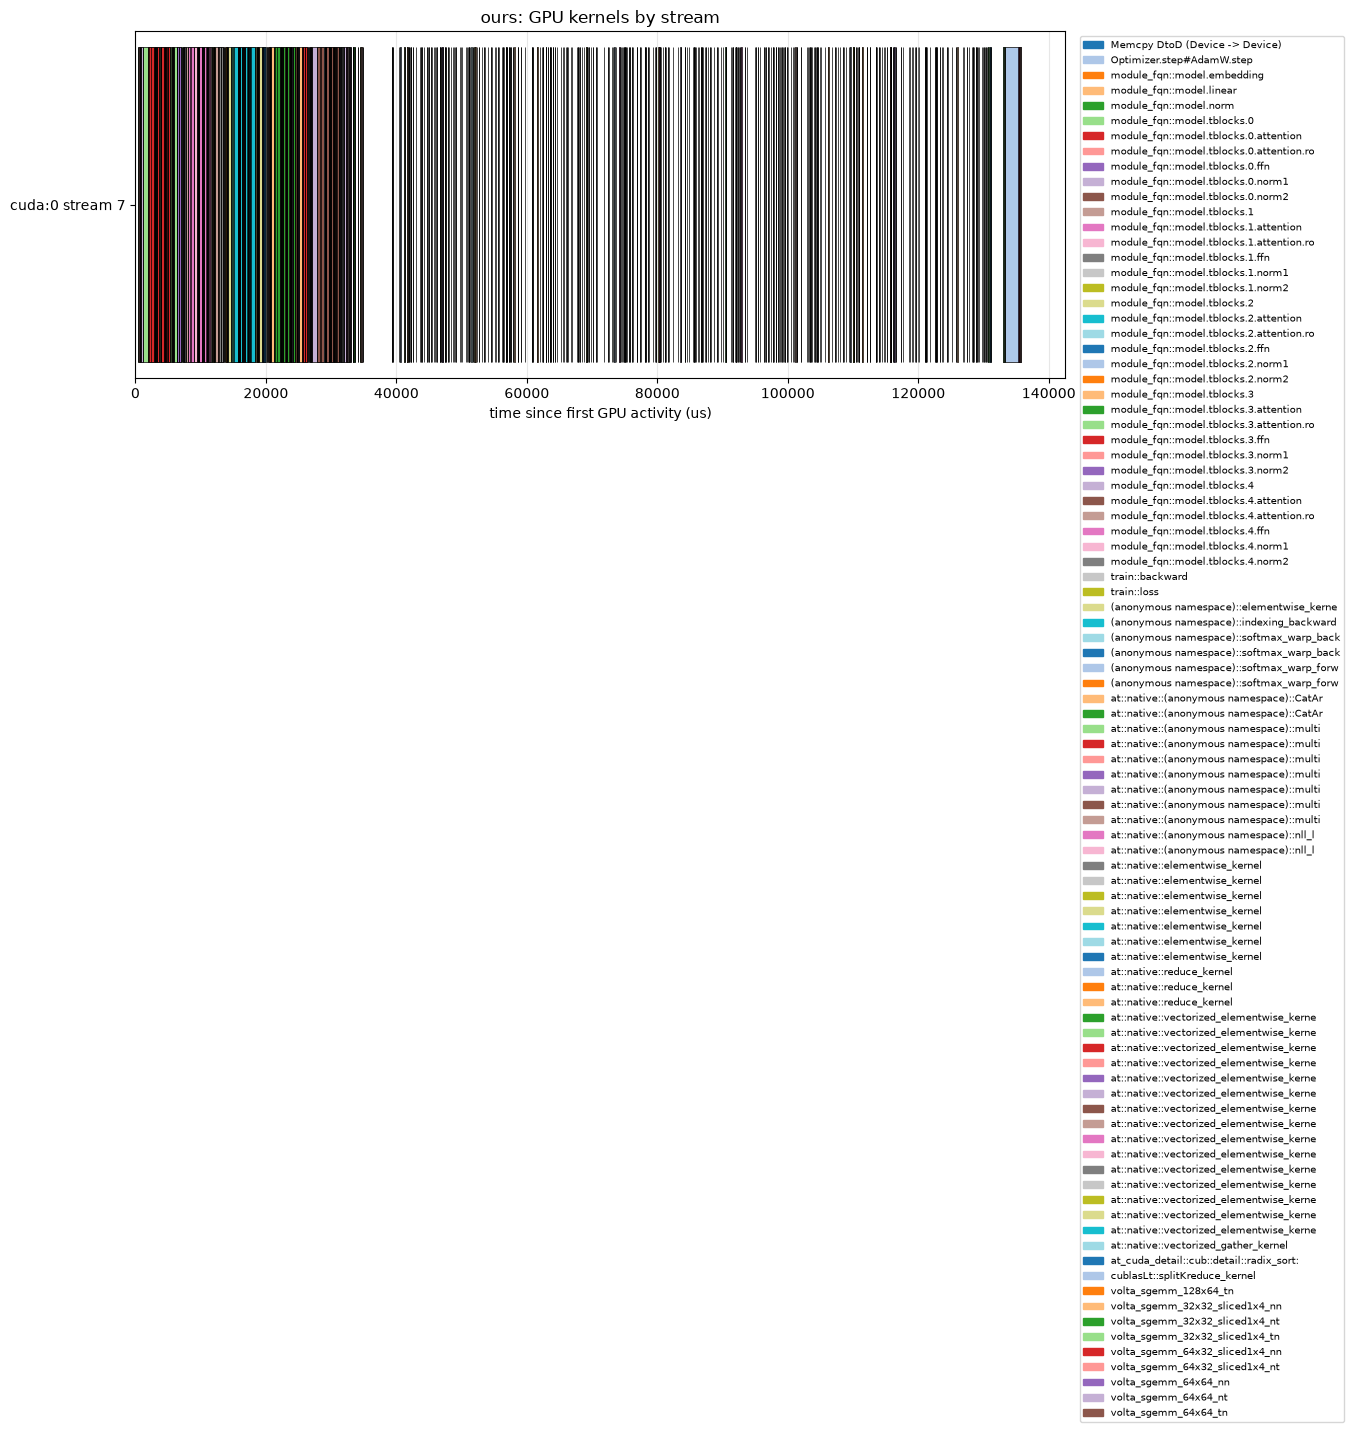

In [7]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

def gpu_span(rows):
    gpu_events = [row for row in rows if row["device_type"] != "DeviceType.CPU"]
    origin = min(row["start_us"] for row in gpu_events)
    return origin, max(row["end_us"] for row in gpu_events) - origin

def plot_stream_timeline(ax, rows, title, origin, xlim):
    gpu_events = [row for row in rows if row["device_type"] != "DeviceType.CPU"]
    streams = sorted({(row["device_index"], row["device_resource_id"]) for row in gpu_events})
    stream_y = {stream: i for i, stream in enumerate(streams)}
    names = sorted({row["name"] for row in gpu_events})
    colors = {name: cm.tab20(i % 20) for i, name in enumerate(names)}

    for row in gpu_events:
        y = stream_y[(row["device_index"], row["device_resource_id"])]
        ax.barh(y, row["duration_us"], left=row["start_us"] - origin, height=0.6,
                color=colors[row["name"]], edgecolor="black", linewidth=0.5)

    ax.set_yticks(range(len(streams)))
    ax.set_yticklabels([f"cuda:{idx} stream {sid}" for idx, sid in streams])
    ax.set_title(title)
    ax.set_xlim(xlim)
    ax.grid(axis="x", alpha=0.3)

    handles = [plt.Rectangle((0, 0), 1, 1, color=colors[name]) for name in names]
    ax.legend(handles, [n.removeprefix("void ").split("<")[0][:40] for n in names],
              loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=7)

origin, span = gpu_span(rows)
fig, ax = plt.subplots(figsize=(12, 4.5))
plot_stream_timeline(ax, rows, f"{model_kind}: GPU kernels by stream",
                     origin, (0, span * 1.05))
ax.set_xlabel("time since first GPU activity (us)")
plt.tight_layout()
plt.show()


In [8]:
def branches(rows):
    """Returns one list per GPU activity: the activity, the operator that launched it, and
    every parent up to the root.

    An activity CUPTI could not correlate has no launcher, so its branch is the activity alone.
    """
    out = []
    for row in rows:
        if row["device_type"] == "DeviceType.CPU":
            continue
        branch, index = [row], row["launcher"]
        while index is not None:
            branch.append(rows[index])
            index = rows[index]["parent"]
        out.append(branch)
    return out

branch_list = branches(rows)
print(f"{len(branch_list)} branches\n")
for branch in branch_list:
    print(f"depth {len(branch)}")
    for r in branch:
        print(f"    {r['index']:>5}  {r['activity_type']:<16} {r['name'][:64]}")
    print()

879 branches

depth 23
      155  kernel           void at::native::vectorized_gather_kernel<16, long>(char*, char*
      149  cpu_op           aten::index
      147  python_function  models/transformer/src/model.py(61): forward
      144  user_annotation  module_fqn::model.embedding
      132  python_function  torch/nn/modules/module.py(1799): inner
      128  python_function  torch/nn/modules/module.py(1787): _call_impl
      127  python_function  nn.Module: Embedding_0
      125  python_function  models/transformer/src/model.py(325): forward
      122  user_annotation  module_fqn::model
      111  python_function  torch/nn/modules/module.py(1799): inner
      107  python_function  torch/nn/modules/module.py(1787): _call_impl
      106  python_function  nn.Module: TransformerLM_0
      104  user_annotation  train::forward
       43  python_function  /var/folders/_9/c3pgt8bn23n2jqgj_1cfghrm0000gn/T/ipykernel_59361
       18  python_function  /var/folders/_9/c3pgt8bn23n2jqgj_1cfghrm000

## Exclusive GPU attribution by module FQN

Run the helper cells above before running the capture. `module_scopes(model)` records attribute paths around
module calls using [PyTorch forward hooks](https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html).
Old captures contain class labels, but not enough information to recover exact FQNs.

Each kernel's owner is the **innermost FQN scope on its launcher's CPU ancestry**.
Functional operations belong to the active module; child-module kernels belong to the
child only. Thus a parent's exclusive row contains only its own work. Repeated calls
aggregate by FQN while keeping separate event indices. Unmatched kernels are returned separately in `unattributed`, with `module_fqn`
and `module_path` set to `None`; their full branches and timing are retained. Memcpy/memset are excluded by default; pass `kernels_only=False`
to include all device activities.

`depth` rolls each exclusive owner up to a dot-separated prefix and groups again.
`model` is depth 1; `model.tblocks.3` is depth 3. Each table is a separate partition:
do not add tables at different depths together. `gpu_time_us` sums kernel durations,
not elapsed wall time or interval hulls; kernels on different streams can overlap.

Our model uses paths such as `model.tblocks.3.attention`; the builtin uses
`model.encoder.layers.3.self_attn`. Shared modules choose an alias beneath the active
caller when possible (e.g. `attention.rope`); aliases under the same caller are
ambiguous and use the first registered path. These are eager forward-call scopes:
direct `.forward()` calls and functional uses of a child's parameters do not enter
that child's scope. Instrumentation adds profiling overhead.

The table has two levels: each module row holds its complete list of `branches`.
Each branch retains its kernel event index, provenance, `start_us`, and `end_us`.
The module row's `start_us` is the earliest kernel start and `end_us` is the latest
kernel end; `span_us` is their difference. These bounding intervals include gaps
and may overlap across groups, while the groups' kernel memberships stay disjoint.


542 unattributed kernels


,index,module_fqn,module_path,branch,kernel,duration_us,start_us,end_us
0,6415,None,None,"[6415, 6412, 6409, 6408, 6407, 6403, 43, 18, 1...","void at::native::elementwise_kernel<128, 2, at...",22.400,38556.416,38578.816
1,6426,None,None,"[6426, 6424, 6422, 6421, 6420, 6417, 6403, 43,...",void (anonymous namespace)::softmax_warp_forwa...,14.944,38680.191,38695.135
2,6432,None,None,"[6432, 6429, 6428, 6427, 6421, 6420, 6417, 640...",void at::native::(anonymous namespace)::nll_lo...,24.384,38745.182,38769.566
3,6485,None,None,"[6485, 6483, 6480, 6479, 6468, 6457, 6455, 645...",void at::native::vectorized_elementwise_kernel...,2.624,39020.987,39023.611
4,6500,None,None,"[6500, 6497, 6496, 6495, 6494, 6493]",void at::native::vectorized_elementwise_kernel...,9.120,43355.717,43364.837


285 attributed kernels


,index,module_fqn,module_path,branch,kernel,duration_us,start_us,end_us
0,155,model.embedding,"[model, model.embedding]","[155, 149, 147, 144, 132, 128, 127, 125, 122, ...","void at::native::vectorized_gather_kernel<16, ...",5.280,4099.626,4104.906
1,209,model.tblocks.0,"[model, model.tblocks.0]","[209, 205, 203, 202, 201, 198, 186, 182, 181, ...",void (anonymous namespace)::elementwise_kernel...,2.880,4470.085,4472.965
2,243,model.tblocks.0.norm1,"[model, model.tblocks.0, model.tblocks.0.norm1]","[243, 238, 237, 235, 232, 229, 217, 213, 212, ...",void at::native::vectorized_elementwise_kernel...,3.360,4724.834,4728.194
3,247,model.tblocks.0.norm1,"[model, model.tblocks.0, model.tblocks.0.norm1]","[247, 245, 244, 232, 229, 217, 213, 212, 201, ...","void at::native::reduce_kernel<512, 1, at::nat...",9.824,4790.753,4800.577
4,250,model.tblocks.0.norm1,"[model, model.tblocks.0, model.tblocks.0.norm1]","[250, 248, 232, 229, 217, 213, 212, 201, 198, ...",void at::native::vectorized_elementwise_kernel...,3.328,4866.560,4869.888
...,...,...,...,...,...,...,...,...
280,6217,model.norm,"[model, model.norm]","[6217, 6215, 6188, 6185, 6173, 6169, 6168, 125...","void at::native::elementwise_kernel<128, 2, at...",4.864,37551.629,37556.493
281,6249,model.norm,"[model, model.norm]","[6249, 6247, 6238, 6237, 6229, 6228, 6223, 618...","void at::native::elementwise_kernel<128, 2, at...",5.024,37712.139,37717.163
282,6337,model.linear,"[model, model.linear]","[6337, 6326, 6307, 6306, 6298, 6297, 6292, 629...",volta_sgemm_128x64_tn,48.384,38242.596,38290.980
283,6675,model.tblocks.3.norm1,"[model, model.tblocks.3, model.tblocks.3.norm1]","[6675, 3848, 3845, 3844, 3842, 3823, 3820, 380...",void at::native::vectorized_elementwise_kernel...,3.328,45988.005,45991.333


,module_fqn,launches,gpu_time_us,start_us,end_us,span_us,branches
0,NaN,542,4107.664,38556.416,139863.998,101307.582,"[{'index': 6415, 'module_fqn': None, 'module_p..."
1,model.tblocks.3,57,350.555,24438.767,51488.353,27049.586,"[{'index': 3800, 'module_fqn': 'model.tblocks...."
2,model.tblocks.0,55,344.385,4470.085,11169.202,6699.117,"[{'index': 209, 'module_fqn': 'model.tblocks.0..."
3,model.tblocks.2,55,344.348,17898.751,24267.953,6369.202,"[{'index': 2603, 'module_fqn': 'model.tblocks...."
4,model.tblocks.1,55,344.160,11338.641,17712.834,6374.193,"[{'index': 1406, 'module_fqn': 'model.tblocks...."
5,model.tblocks.4,55,343.710,30717.217,37207.697,6490.480,"[{'index': 4997, 'module_fqn': 'model.tblocks...."
6,model.linear,1,48.384,38242.596,38290.980,48.384,"[{'index': 6337, 'module_fqn': 'model.linear',..."
7,model.norm,6,29.376,37392.975,37717.163,324.188,"[{'index': 6199, 'module_fqn': 'model.norm', '..."
8,model.embedding,1,5.280,4099.626,4104.906,5.280,"[{'index': 155, 'module_fqn': 'model.embedding..."


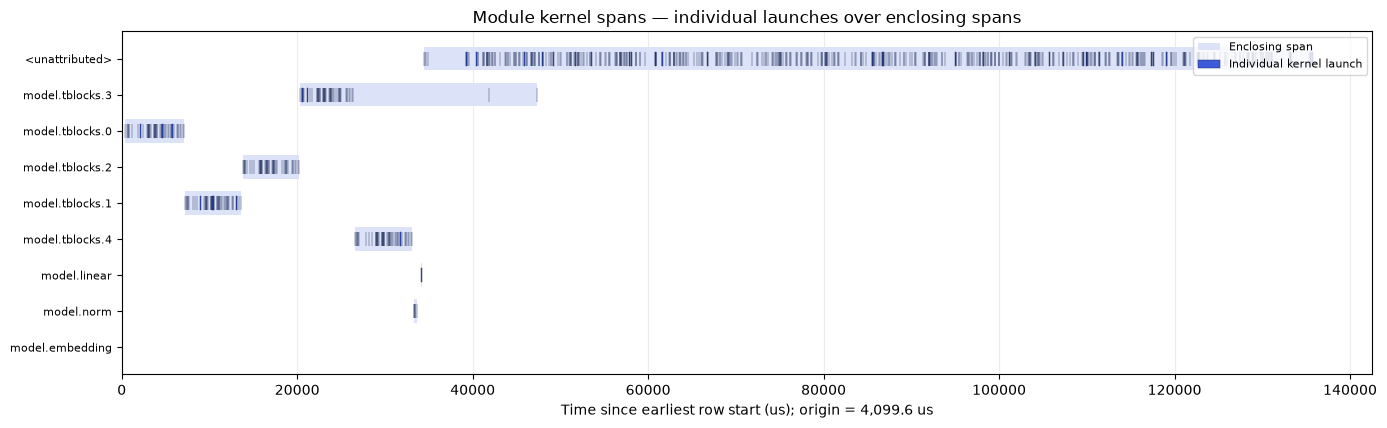

<Axes: title={'center': 'Module kernel spans — individual launches over enclosing spans'}, xlabel='Time since earliest row start (us); origin = 4,099.6 us'>

In [15]:
import math
import pandas as pd

attributed, unattributed = module_branches(rows)
all_branches = attributed + unattributed

expected = {r["index"] for r in rows
            if r["device_type"] != "DeviceType.CPU" and r["activity_type"] == "kernel"}
assert {b["index"] for b in all_branches} == expected


def module_table(depth=None):
    groups = aggregate_modules(all_branches, depth=depth)
    seen = set()
    for group in groups:
        members = set(group["event_indices"])
        assert len(members) == group["launches"] == len(group["event_indices"])
        assert seen.isdisjoint(members), f"Overlapping kernels in {group['module_fqn']}"
        assert [b["index"] for b in group["branches"]] == group["event_indices"]
        assert group["start_us"] == min(b["start_us"] for b in group["branches"])
        assert group["end_us"] == max(b["end_us"] for b in group["branches"])
        seen.update(members)
    assert seen == expected, "Module groups must partition all captured kernels"
    placed = [i for g in groups for i in g["event_indices"]]
    assert len(placed) == len(set(placed)) == len(expected)
    assert set(placed) == expected
    assert math.isclose(sum(g["gpu_time_us"] for g in groups),
                        sum(b["duration_us"] for b in all_branches))
    return pd.DataFrame(groups, columns=[
        "module_fqn", "launches", "gpu_time_us", "start_us", "end_us",
        "span_us", "branches", "event_indices",
    ]).drop(columns="event_indices")


def display_timeline(table, title="Module kernel spans"):
    """Display enclosing spans with individual kernel intervals overlaid per row.

    Also accepts a DataFrame of an individual group's branches.
    """
    import matplotlib.pyplot as plt

    display(table)
    if table.empty:
        return
    origin = table["start_us"].min()
    labels = []
    for _, row in table.iterrows():
        module = row.get("module_fqn")
        module = "<unattributed>" if pd.isna(module) else module
        if "kernel" in table.columns:
            labels.append(f"#{row['index']} {row['kernel']}")
        else:
            labels.append(module)
    fig, ax = plt.subplots(figsize=(14, max(2.5, 0.32 * len(table) + 1.5)))
    ax.barh(range(len(table)), table["end_us"] - table["start_us"],
            left=table["start_us"] - origin, height=0.65,
            color="#dce3f8", label="Enclosing span", zorder=1)
    # One rectangle per launch; preserve exact timestamps and gaps.
    for y, (_, row) in enumerate(table.iterrows()):
        launches = row["branches"] if "branches" in table.columns else [row]
        ax.barh([y] * len(launches),
                [b["end_us"] - b["start_us"] for b in launches],
                left=[b["start_us"] - origin for b in launches],
                height=0.38, color="#3b5bdb", edgecolor="#172554",
                linewidth=0.3, zorder=2,
                label="Individual kernel launch" if y == 0 else None)
    ax.legend(loc="upper right", fontsize=8)
    ax.set_yticks(range(len(table)), labels=labels, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlabel(f"Time since earliest row start (us); origin = {origin:,.1f} us")
    ax.set_title(title + " — individual launches over enclosing spans")
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)
    fig.tight_layout()
    plt.show()
    return ax

print(f"{len(unattributed)} unattributed kernels")
display(pd.DataFrame(unattributed).head())
print(f"{len(attributed)} attributed kernels")
display(pd.DataFrame(attributed))

display_timeline(module_table(3))

In [ ]:
disp

In [10]:
df = pd.DataFrame(all_branches)[['index','module_fqn','kernel','branch']]

In [11]:
calls = pd.concat([pd.DataFrame(rows).loc[df.loc[i,'branch'],['name','device_type','activity_type','launcher','input_shapes','flops','stack']] for i in range(len(df))])

In [12]:
def preview(df, filter_names=False):
    view = df
    if filter_names:
        view = view[view["name"].str.contains("::", regex=False, na=False)]
        view['index_']=view.index

    view = view.reset_index(drop=True)
    if not view.columns.is_unique:
        raise ValueError("Duplicate column names; rename them before styling.")

    display(view.style.apply(
        lambda row: [
            "background-color: #fff3cd; color: #111"
            if row["activity_type"] == "kernel" else ""
        ] * len(row),
        axis=1,
        
    ))

preview(calls,filter_names=True)

,name,device_type,activity_type,launcher,input_shapes,flops,stack,index_
0,"void at::native::vectorized_gather_kernel<16, long>(char*, char*, long*, int, long, long, long, long, bool)",DeviceType.CUDA,kernel,149.000000,[],0,[],155
1,aten::index,DeviceType.CPU,cpu_op,nan,"[[1000, 64], []]",0,[],149
2,module_fqn::model.embedding,DeviceType.CPU,user_annotation,nan,[],0,[],144
3,module_fqn::model,DeviceType.CPU,user_annotation,nan,[],0,[],122
4,train::forward,DeviceType.CPU,user_annotation,nan,[],0,[],104
5,"void (anonymous namespace)::elementwise_kernel_with_index(int, at::native::arange_cuda_out(c10::Scalar const&, c10::Scalar const&, c10::Scalar const&, at::Tensor&)::{lambda()#1}::operator()() const::{lambda()#4}::operator()() const::{lambda(long)#1}, function_traits::result_type*)",DeviceType.CUDA,kernel,205.000000,[],0,[],209
6,aten::arange,DeviceType.CPU,cpu_op,nan,"[[], [], [], [0]]",0,[],205
7,aten::arange,DeviceType.CPU,cpu_op,nan,"[[], [], [], [], []]",0,[],203
8,module_fqn::model.tblocks.0,DeviceType.CPU,user_annotation,nan,[],0,[],198
9,module_fqn::model,DeviceType.CPU,user_annotation,nan,[],0,[],122
